Please upload your input image (e.g., input.jpg):


Saving test_image.jpg to test_image.jpg


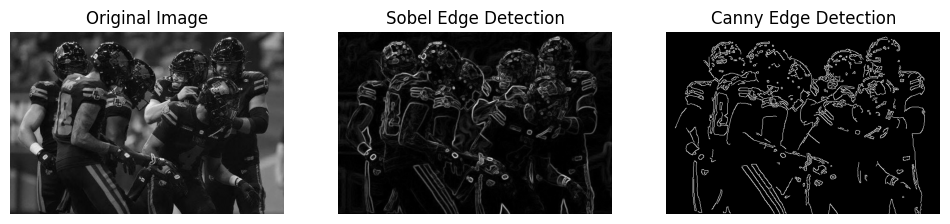

In [ ]:
import cv2
import matplotlib.pyplot as plt
from google.colab import files

print("Please upload your input image (e.g., input.jpg):")
uploaded = files.upload()
image_path = next(iter(uploaded))

def edge_detection(image_path):
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        print("Error: Image not found or path is incorrect.")
        return

    # Apply Gaussian blur to reduce noise
    img_blur = cv2.GaussianBlur(img, (3, 3), 0)

    # Sobel edge detection (detects edges along x and y gradient directions)
    sobelx = cv2.Sobel(img_blur, cv2.CV_64F, 1, 0, ksize=3)
    sobely = cv2.Sobel(img_blur, cv2.CV_64F, 0, 1, ksize=3)
    sobel_combined = cv2.magnitude(sobelx, sobely)
    # Canny edge detection (detects strong edges using gradient and thresholding)
    edges_canny = cv2.Canny(img_blur, 100, 200)

    # Display results using matplotlib
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 3, 1)
    plt.imshow(img, cmap='gray')
    plt.title('Original Image')
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(sobel_combined, cmap='gray')
    plt.title('Sobel Edge Detection')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(edges_canny, cmap='gray')
    plt.title('Canny Edge Detection')
    plt.axis('off')

    plt.show()

# Execute the function with the dynamically uploaded file
edge_detection(image_path)